# Определение авторства с использованием сжатия

Воспроизведение результатов статьи:
> Ryabko, B.; Savina, N. Using Data Compression to Build a Method for Statistically Verified Attribution of Literary Texts. Entropy 2021, 23, 1302.

## Цели проекта
- **(a)** Воспроизвести результаты статьи
- **(b)** Исследовать влияние выбора метода сжатия (включая нейросетевые)
- **(c)** Рассмотреть задачу выбора лучшего перевода для данного автора

In [1]:
import sys
sys.path.insert(0, 'src')

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from theory import phi, phi_authors, build_table, chi_square, significance_level, get_accuracy
from preprocessing import run_data_pipeline, split_into_slices
from data_pipeline import process

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

## 1. Подготовка данных

### 1.1 Списки авторов

In [2]:
# Авторы 1915-1940 годов (Таблица 1 в статье)
AUTHORS_1915_1940 = [
    'Pasternak', 'Nabokov', 'Paustovsky', 'Veresayev', 'Zamyatin',
    'Bunin', 'Gorky', 'Kuprin', 'Platonov', 'Mandelstam',
    'Olesha', 'Katayev', 'Green', 'Zhitkov', 'Ehrenburg',
    'Tynyanov', 'Gaidar'
]

# Авторы для задачи атрибуции Ильф/Петров vs Булгаков (Таблицы 3-5)
AUTHORS_BULGAKOV = ['Bulgakov', 'Ilf_and_Petrov']

# Авторы 19 века (Таблица 6)
AUTHORS_19_CENTURY = [
    'Nekrasov', 'Panaeva', 'Turgenev', 'Goncharov', 'Gogol', 'Dahl',
    'Dostoevsky', 'Panaev', 'SShchedrin', 'Tolstoy'
]

# Типы предобработки
PREPROCESS_TYPES = [
    'lower_nopunct_nostop',
    'lower_nopunct_withstop',
    'origcase_nopunct_nostop',
    'origcase_nopunct_withstop',
    'lower_withpunct_nostop',
    'origcase_withpunct_nostop',
    'lower_withpunct_withstop',
    'origcase_withpunct_withstop'
]

# Компрессоры
COMPRESSORS = ['gzip', 'bzip2', 'lzma', 'zstd', 'brotli', 'paq']

### 1.2 Генерация датасетов

In [ ]:
TRAIN_KB = 64
TEST_KB = 64
N_SLICES = 16

# # Раскомментируйте для генерации данных:
# run_data_pipeline(AUTHORS_1915_1940, train_kb=TRAIN_KB, test_kb=TEST_KB)
# split_into_slices(AUTHORS_1915_1940, n_slices=N_SLICES)

Генерация датасета
Для Pasternak!
Готово! Сохранено в папке data/processed/Pasternak/lower_nopunct_nostop
В train попали: ['Охранная грамота', 'Детство Люверс', 'Доктор Живаго']
В test: ['Воздушные пути', 'Повесть']
Готово! Сохранено в папке data/processed/Pasternak/lower_nopunct_withstop
В train попали: ['Охранная грамота', 'Детство Люверс', 'Доктор Живаго']
В test: ['Воздушные пути', 'Повесть']
Готово! Сохранено в папке data/processed/Pasternak/origcase_nopunct_nostop
В train попали: ['Охранная грамота', 'Детство Люверс', 'Доктор Живаго']
В test: ['Воздушные пути', 'Повесть']
Готово! Сохранено в папке data/processed/Pasternak/origcase_nopunct_withstop
В train попали: ['Охранная грамота', 'Детство Люверс', 'Доктор Живаго']
В test: ['Воздушные пути', 'Повесть']
Готово! Сохранено в папке data/processed/Pasternak/lower_withpunct_nostop
В train попали: ['Охранная грамота', 'Детство Люверс', 'Доктор Живаго']
В test: ['Воздушные пути', 'Повесть']
Готово! Сохранено в папке data/processed/Pas

---
## 2. Эксперимент 1: Таблица 1 (17 авторов 1915-1940)

In [4]:
def run_experiment(authors, preprocess_type, n_slices, compressor, lvl=6):
    table = build_table(authors, preprocess_type, n_slices, compressor, lvl)
    chi2, p_value, df = significance_level(table)
    accuracy = get_accuracy(table)
    return {
        'table': table,
        'chi2': chi2,
        'p_value': p_value,
        'df': df,
        'accuracy': accuracy
    }

In [5]:
result = run_experiment(
    authors=AUTHORS_1915_1940,
    preprocess_type='origcase_nopunct_withstop',
    n_slices=16,
    compressor='lzma',
    lvl=6
)
print(f"chi2 = {result['chi2']:.1f}, p-value = {result['p_value']:.2e}, Accuracy = {result['accuracy']:.2%}")
result['table']

chi2 = 1431.8, p-value = 0.00e+00, Accuracy = 48.53%


,Pasternak,Nabokov,Paustovsky,Veresayev,Zamyatin,Bunin,Gorky,Kuprin,Platonov,Mandelstam,Olesha,Katayev,Green,Zhitkov,Ehrenburg,Tynyanov,Gaidar
Pasternak,12,0,0,0,0,0,0,0,0,0,0,0,4,0,0,0,0
Nabokov,4,4,0,0,0,1,0,2,0,2,0,0,3,0,0,0,0
Paustovsky,1,1,10,0,0,0,0,0,0,1,0,0,2,0,0,0,1
Veresayev,1,0,0,1,0,1,0,8,1,1,0,0,0,0,3,0,0
Zamyatin,1,0,0,3,12,0,0,0,0,0,0,0,0,0,0,0,0
Bunin,3,2,0,1,0,3,1,6,0,0,0,0,0,0,0,0,0
Gorky,0,1,0,1,0,1,8,2,0,1,0,1,0,0,1,0,0
Kuprin,3,0,0,2,0,0,0,10,0,0,0,0,1,0,0,0,0
Platonov,2,0,0,0,0,0,3,0,11,0,0,0,0,0,0,0,0
Mandelstam,5,0,1,0,0,0,0,0,0,8,2,0,0,0,0,0,0


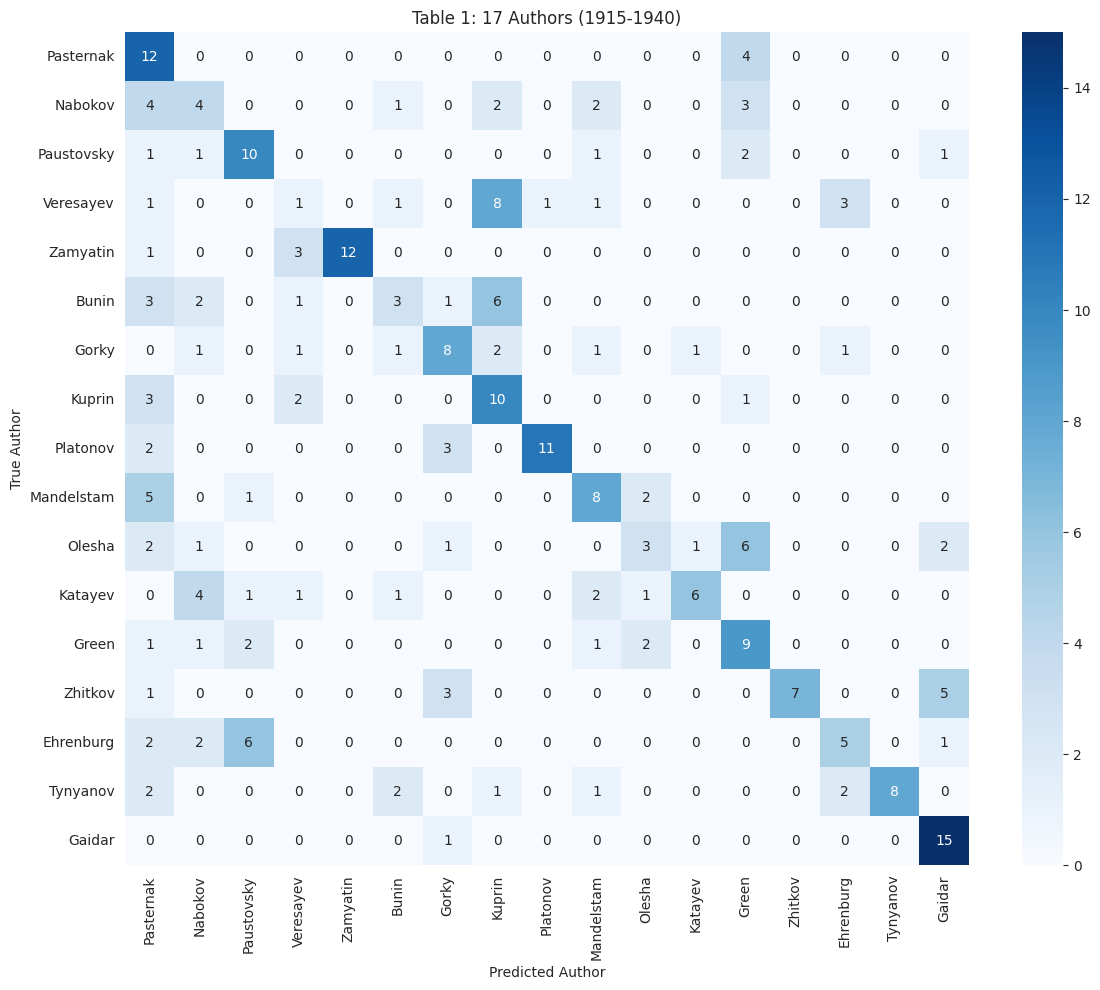

In [6]:
def plot_confusion_matrix(table, title='Confusion Matrix'):
    plt.figure(figsize=(12, 10))
    sns.heatmap(table, annot=True, fmt='d', cmap='Blues')
    plt.title(title)
    plt.xlabel('Predicted Author')
    plt.ylabel('True Author')
    plt.tight_layout()
    plt.show()

plot_confusion_matrix(result['table'], 'Table 1: 17 Authors (1915-1940)')

### 2.1 Сравнение типов предобработки (Таблица 2)

In [16]:
TRAIN_KB = 64
TEST_KB = 64
N_SLICES = 16

run_data_pipeline(AUTHORS_1915_1940, train_kb=TRAIN_KB, test_kb=TEST_KB, seed=42)
split_into_slices(AUTHORS_1915_1940, n_slices=N_SLICES)

Генерация датасета
Для Bunin!
Готово! Сохранено в папке data/processed/Bunin/lower_nopunct_nostop
В train попали: ['Митина любовь', 'Жизнь Арсеньева', 'Легкое дыхание', 'Суходол']
В test: ['Деревня', 'Темные аллеи']
Готово! Сохранено в папке data/processed/Bunin/lower_nopunct_withstop
В train попали: ['Митина любовь', 'Жизнь Арсеньева', 'Легкое дыхание', 'Суходол']
В test: ['Деревня', 'Темные аллеи']
Готово! Сохранено в папке data/processed/Bunin/origcase_nopunct_nostop
В train попали: ['Митина любовь', 'Жизнь Арсеньева', 'Легкое дыхание', 'Суходол']
В test: ['Деревня', 'Темные аллеи']
Готово! Сохранено в папке data/processed/Bunin/origcase_nopunct_withstop
В train попали: ['Митина любовь', 'Жизнь Арсеньева', 'Легкое дыхание', 'Суходол']
В test: ['Деревня', 'Темные аллеи']
Готово! Сохранено в папке data/processed/Bunin/lower_withpunct_nostop
В train попали: ['Митина любовь', 'Жизнь Арсеньева', 'Легкое дыхание', 'Суходол']
В test: ['Деревня', 'Темные аллеи']
Готово! Сохранено в папке da

In [8]:
def compare_preprocessing(authors, n_slices, compressor, lvl=6):
    results = []
    for preprocess_type in PREPROCESS_TYPES:
        try:
            res = run_experiment(authors, preprocess_type, n_slices, compressor, lvl)
            results.append({
                'preprocessing': preprocess_type,
                'chi2': res['chi2'],
                'accuracy': res['accuracy'],
                'p_value': res['p_value']
            })
        except FileNotFoundError as e:
            print(f"Skipping {preprocess_type}: {e}")
    return pd.DataFrame(results).sort_values('chi2', ascending=False)

preprocessing_comparison = compare_preprocessing(AUTHORS_1915_1940, 16, 'lzma')
preprocessing_comparison

,preprocessing,chi2,accuracy,p_value
6,lower_withpunct_withstop,1769.257185,0.573529,0.0
7,origcase_withpunct_withstop,1763.033107,0.566176,0.0
4,lower_withpunct_nostop,1472.733614,0.496324,0.0
5,origcase_withpunct_nostop,1455.476470,0.492647,0.0
3,origcase_nopunct_withstop,1431.788858,0.485294,0.0
1,lower_nopunct_withstop,1377.601834,0.485294,0.0
0,lower_nopunct_nostop,1255.690704,0.437500,0.0
2,origcase_nopunct_nostop,1242.625075,0.441176,0.0


### 2.2 Сравнение компрессоров

In [8]:
def compare_compressors(authors, preprocess_type, n_slices):
    results = []
    compressor_levels = {
        'gzip': 6, 'bzip2': 6, 'lzma': 6,
        'zstd': 10, 'brotli': 6, 'paq': 1
    }
    for compressor, lvl in compressor_levels.items():
        try:
            print(f"Testing {compressor}...")
            res = run_experiment(authors, preprocess_type, n_slices, compressor, lvl)
            results.append({
                'compressor': compressor,
                'chi2': res['chi2'],
                'accuracy': res['accuracy'],
                'p_value': res['p_value']
            })
        except Exception as e:
            print(f"Error with {compressor}: {e}")
    return pd.DataFrame(results).sort_values('chi2', ascending=False)

compressor_comparison = compare_compressors(AUTHORS_1915_1940, 'origcase_withpunct_withstop', 16)
compressor_comparison

Testing gzip...


/home/platon/Documents/TI/information-theory-determining-authorship-using-compression/src/theory.py:118: RuntimeWarning: invalid value encountered in divide
  chi2_val = ((A - expected)**2 / expected).sum()


Testing bzip2...
Testing lzma...
Testing zstd...
Testing brotli...
Testing paq...


,compressor,chi2,accuracy,p_value
5,paq,1721.718516,0.547794,0.0
2,lzma,1431.788858,0.485294,0.0
3,zstd,1255.650303,0.452206,0.0
4,brotli,1207.409862,0.430147,0.0
0,gzip,NaN,0.341912,NaN
1,bzip2,NaN,0.301471,NaN


In [ ]:
present_table = compressor_comparison.copy()

# Переименовываем столбцы
present_table = present_table.rename(columns={
    'compressor': 'Компрессор',
    'chi2': 'χ²',
    'accuracy': 'Accuracy',
    'p_value': 'P-value'
})

present_table['χ²'] = present_table['χ²'].round(3)
present_table['Accuracy'] = present_table['Accuracy'].round(3)

present_table

,Компрессор,χ²,Accuracy,P-value
5,paq,2355.911,0.713,0.0
2,lzma,2039.546,0.643,0.0
3,zstd,1651.507,0.566,0.0
4,brotli,1457.457,0.537,0.0
1,bzip2,1167.252,0.460,0.0
0,gzip,932.909,0.393,0.0


In [15]:
TRAIN_KB = 64
TEST_KB = 16
N_SLICES = 4

curr_authors = AUTHORS_1915_1940[:2]

run_data_pipeline(curr_authors, train_kb=TRAIN_KB, test_kb=TEST_KB, seed=42)
split_into_slices(curr_authors, n_slices=N_SLICES)

Генерация датасета
Для Nabokov!
Готово! Сохранено в папке data/processed/Nabokov/lower_nopunct_nostop
В train попали: ['Отчаяние', 'Король, дама. валет', 'Машенька']
В test: ['Соглядатай', 'Защита Лужина']
Готово! Сохранено в папке data/processed/Nabokov/lower_nopunct_withstop
В train попали: ['Отчаяние', 'Король, дама. валет', 'Машенька']
В test: ['Соглядатай', 'Защита Лужина']
Готово! Сохранено в папке data/processed/Nabokov/origcase_nopunct_nostop
В train попали: ['Отчаяние', 'Король, дама. валет', 'Машенька']
В test: ['Соглядатай', 'Защита Лужина']
Готово! Сохранено в папке data/processed/Nabokov/origcase_nopunct_withstop
В train попали: ['Отчаяние', 'Король, дама. валет', 'Машенька']
В test: ['Соглядатай', 'Защита Лужина']
Готово! Сохранено в папке data/processed/Nabokov/lower_withpunct_nostop
В train попали: ['Отчаяние', 'Король, дама. валет', 'Машенька']
В test: ['Соглядатай', 'Защита Лужина']
Готово! Сохранено в папке data/processed/Nabokov/origcase_withpunct_nostop
В train поп

In [ ]:
def compare_compressors(authors, preprocess_type, n_slices, compression_types):
    results = []
    compressor_levels = {
        'gzip': 5, 'bzip2': 5, 'lzma': 5,
        'zstd': 9, 'brotli': 5, 'paq': 1,
        
        'cmix': 1,'nncp': 3
    }
    for compressor, lvl in compressor_levels.items():
        if compressor in compression_types:
            try:
                print(f"Testing {compressor}...")
                res = run_experiment(authors, preprocess_type, n_slices, compressor, lvl)
                results.append({
                    'compressor': compressor,
                    'chi2': res['chi2'],
                    'accuracy': res['accuracy'],
                    'p_value': res['p_value']
                })
                # Освобождаем память после нейросетевых компрессоров
                if compressor in ('paq', 'llm', 'ts_zip'):
                    clear_model_cache()
            except Exception as e:
                print(f"Error with {compressor}: {e}")
    return pd.DataFrame(results).sort_values('chi2', ascending=False)

In [21]:
compressor_comparison = compare_compressors(curr_authors, 'origcase_withpunct_withstop', N_SLICES, compression_types=['nncp'])
compressor_comparison

Testing nncp...


,compressor,chi2,accuracy,p_value
0,nncp,0.0,0.5,1.0


In [22]:
compressor_comparison = compare_compressors(curr_authors, 'origcase_withpunct_withstop', N_SLICES, compression_types=['cmix'])
compressor_comparison

Testing cmix...


,compressor,chi2,accuracy,p_value
0,cmix,8.0,1.0,0.004678


In [23]:
compressor_comparison = compare_compressors(curr_authors, 'origcase_withpunct_withstop', N_SLICES, compression_types=['lzma'])
compressor_comparison

Testing lzma...


,compressor,chi2,accuracy,p_value
0,lzma,4.8,0.875,0.02846


In [24]:
compressor_comparison = compare_compressors(curr_authors, 'origcase_withpunct_withstop', N_SLICES, compression_types=['paq'])
compressor_comparison

Testing paq...


,compressor,chi2,accuracy,p_value
0,paq,8.0,1.0,0.004678


### 2.3 Сравнение размеров

In [ ]:
def compare_size(authors, preprocess_type, n_slices, compressor, lvl=4):
    results = []
    for size in [32, 64, 128, 256]:
        try:
            run_data_pipeline(AUTHORS_1915_1940, train_kb=size, test_kb=size, seed=42)
            split_into_slices(AUTHORS_1915_1940, n_slices=n_slices)
            res = run_experiment(authors, preprocess_type, n_slices, compressor, lvl)
            results.append({
                'size': size,
                'chi2': res['chi2'],
                'accuracy': res['accuracy'],
                'p_value': res['p_value']
            })
        except FileNotFoundError as e:
            print(f"Skipping {preprocess_type}: {e}")
    return pd.DataFrame(results).sort_values('chi2', ascending=False)

size_comparison = compare_size(AUTHORS_1915_1940, 'origcase_withpunct_withstop', 16, 'lzma')
size_comparison

Генерация датасета
Для Bunin!
Готово! Сохранено в папке data\processed\Bunin\lower_nopunct_nostop
В train попали: ['Митина любовь', 'Жизнь Арсеньева', 'Легкое дыхание', 'Суходол']
В test: ['Деревня', 'Темные аллеи']
Готово! Сохранено в папке data\processed\Bunin\lower_nopunct_withstop
В train попали: ['Митина любовь', 'Жизнь Арсеньева', 'Легкое дыхание', 'Суходол']
В test: ['Деревня', 'Темные аллеи']
Готово! Сохранено в папке data\processed\Bunin\origcase_nopunct_nostop
В train попали: ['Митина любовь', 'Жизнь Арсеньева', 'Легкое дыхание', 'Суходол']
В test: ['Деревня', 'Темные аллеи']
Готово! Сохранено в папке data\processed\Bunin\origcase_nopunct_withstop
В train попали: ['Митина любовь', 'Жизнь Арсеньева', 'Легкое дыхание', 'Суходол']
В test: ['Деревня', 'Темные аллеи']
Готово! Сохранено в папке data\processed\Bunin\lower_withpunct_nostop
В train попали: ['Митина любовь', 'Жизнь Арсеньева', 'Легкое дыхание', 'Суходол']
В test: ['Деревня', 'Темные аллеи']
Готово! Сохранено в папке da

,size,chi2,accuracy,p_value
3,256,3814.096681,0.930147,0.0
2,128,3312.962502,0.863971,0.0
1,64,2222.315310,0.683824,0.0
0,32,1513.161979,0.511029,0.0


In [ ]:
present_table = size_comparison.copy()

# Переименовываем столбцы
present_table = present_table.rename(columns={
    'size': 'Размер',
    'chi2': 'χ²',
    'accuracy': 'Accuracy',
    'p_value': 'P-value'
})

present_table['χ²'] = present_table['χ²'].round(3)
present_table['Accuracy'] = present_table['Accuracy'].round(3)

present_table

,Размер,χ²,Accuracy,P-value
3,256,3814.097,0.930,0.0
2,128,3312.963,0.864,0.0
1,64,2222.315,0.684,0.0
0,32,1513.162,0.511,0.0


---
## 3. Эксперимент 2: Булгаков vs Ильф/Петров (Таблицы 3-5)

In [ ]:
def attribution_experiment(authors, disputed_slices_dir, preprocess_type, n_slices, compressor, lvl=6):
    authors_paths = {}
    for author in authors:
        train_path = Path('data/processed') / author / preprocess_type / 'Train.txt'
        if train_path.exists():
            authors_paths[author] = train_path
    
    attribution_counts = {author: 0 for author in authors}
    slices_path = Path(disputed_slices_dir)
    
    for i in range(n_slices):
        slice_path = slices_path / f'{i}_slice.txt'
        if not slice_path.exists():
            continue
        phi_vals = phi_authors(compressor, authors_paths, slice_path, lvl)
        predicted_author = min(phi_vals, key=phi_vals.get)
        attribution_counts[predicted_author] += 1
    
    return attribution_counts

In [ ]:
# Таблица 4: Кросс-проверка
result_cross = run_experiment(AUTHORS_BULGAKOV, 'origcase_nopunct_withstop', 64, 'lzma')
result_cross['table']

FileNotFoundError: Слайс 0 у автора Bulgakov не найден: data/processed/Bulgakov/origcase_nopunct_withstop/64_slices/0_slice.txt

---
## 4. Эксперимент 3: Некрасов/Панаева (Таблицы 6-8)

In [ ]:
result_19c = run_experiment(AUTHORS_19_CENTURY, 'origcase_nopunct_withstop', 16, 'lzma')
print(f"chi2 = {result_19c['chi2']:.1f}")
result_19c['table']

FileNotFoundError: Слайс 0 у автора Nekrasov не найден: data/processed/Nekrasov/origcase_nopunct_withstop/16_slices/0_slice.txt

In [ ]:
def attribute_chapters(authors, chapters_paths, preprocess_type, n_slices, compressor, lvl=6):
    results = []
    for chapter_name, chapter_path in chapters_paths.items():
        counts = attribution_experiment(authors, chapter_path, preprocess_type, n_slices, compressor, lvl)
        row = {'chapter': chapter_name}
        row.update(counts)
        results.append(row)
    return pd.DataFrame(results).set_index('chapter')

---
## 5. Сравнение методов сжатия (Цель b)

In [ ]:
def plot_compressor_comparison(results):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    axes[0].bar(results['compressor'], results['chi2'], color='steelblue')
    axes[0].set_xlabel('Compressor')
    axes[0].set_ylabel('chi2')
    axes[0].set_title('chi2 by Compressor')
    axes[0].tick_params(axis='x', rotation=45)
    
    axes[1].bar(results['compressor'], results['accuracy'] * 100, color='forestgreen')
    axes[1].set_xlabel('Compressor')
    axes[1].set_ylabel('Accuracy (%)')
    axes[1].set_title('Accuracy by Compressor')
    axes[1].tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    plt.show()

---
## 6. Задача выбора лучшего перевода (Цель c)

In [ ]:
def compare_translations(original_author_path, translations_paths, compressor='lzma', lvl=6):
    results = {}
    original_path = Path(original_author_path)
    
    for translator, translation_path in translations_paths.items():
        phi_val = phi(compressor, original_path, Path(translation_path), lvl)
        results[translator] = phi_val
    
    return dict(sorted(results.items(), key=lambda x: x[1]))

---
## 7. Итоговый отчёт

In [ ]:
def summary_report(experiments_results):
    print("=" * 60)
    print("SUMMARY REPORT")
    print("=" * 60)
    
    for name, result in experiments_results.items():
        print(f"\n{name}:")
        print(f"  chi2 = {result['chi2']:.1f}")
        print(f"  p-value = {result['p_value']:.2e}")
        print(f"  Accuracy = {result['accuracy']:.2%}")
        
        if result['p_value'] < 0.000001:
            print(f"  -> H0 rejected at significance level 0.000001")
        elif result['p_value'] < 0.01:
            print(f"  -> H0 rejected at significance level 0.01")